In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np

In [2]:
df=pd.read_csv('https://raw.githubusercontent.com/rashakil-ds/Public-Datasets/refs/heads/main/churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
#df.info()

In [4]:
from ydata_profiling import ProfileReport

In [5]:
profile=ProfileReport(df)

In [6]:
#profile

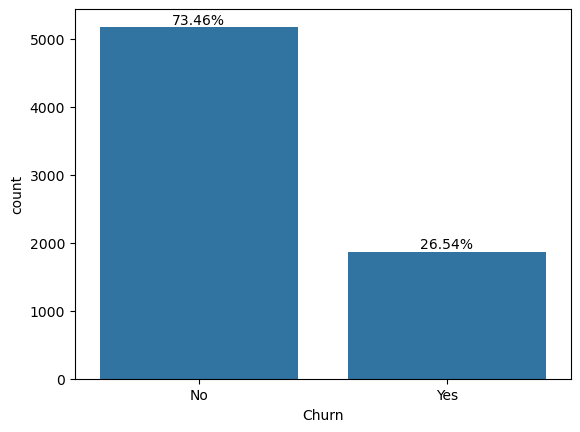

In [7]:
ax=sns.countplot(data=df,x=df['Churn'])
total_customer=df['Churn'].value_counts().sum()
# Add text labels above the bars
for p in ax.patches:
    ax.annotate(f'{(p.get_height()*100)/total_customer:.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom')

plt.show()

In [8]:
#df['Churn'].value_counts().sum()
df['gender'].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

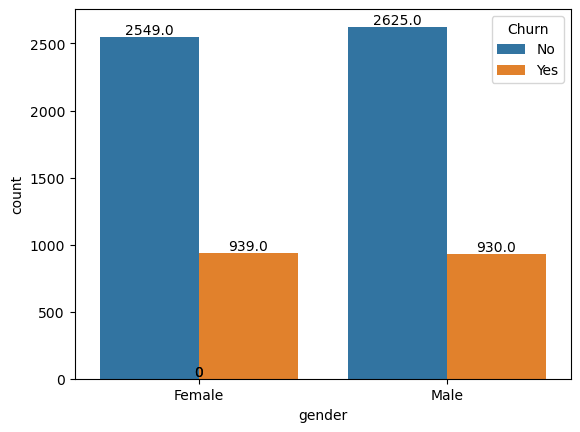

In [9]:
ax=sns.countplot(data=df,x='gender',hue='Churn')
# Add text labels above the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom')

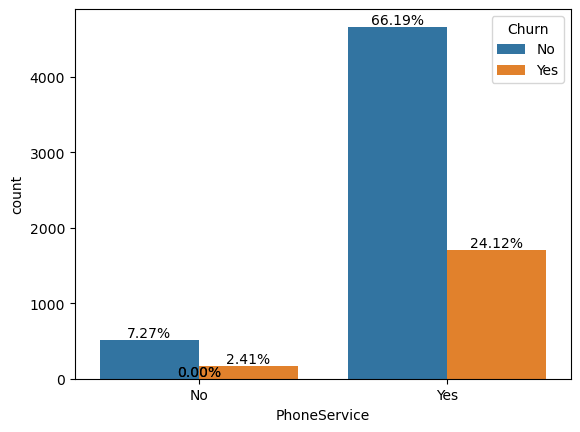

In [10]:
ax=sns.countplot(data=df,x='PhoneService',hue='Churn')
# Add text labels above the bars
total_customer=df['PhoneService'].value_counts().sum()
# Add text labels above the bars
for p in ax.patches:
    ax.annotate(f'{(p.get_height()*100)/total_customer:.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom')

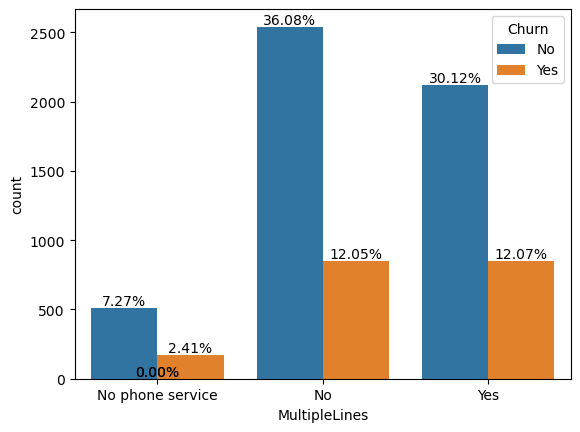

In [11]:
ax=sns.countplot(data=df,x='MultipleLines',hue='Churn')
# Add text labels above the bars
total_customer=df['MultipleLines'].value_counts().sum()
# Add text labels above the bars
for p in ax.patches:
    ax.annotate(f'{(p.get_height()*100)/total_customer:.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom')

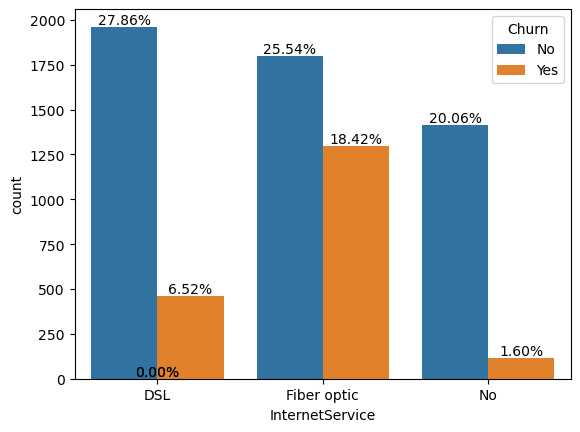

In [12]:
ax=sns.countplot(data=df,x='InternetService',hue='Churn')
# Add text labels above the bars
total_customer=df['InternetService'].value_counts().sum()
# Add text labels above the bars
for p in ax.patches:
    ax.annotate(f'{(p.get_height()*100)/total_customer:.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom')

In [13]:
df=df.drop(['customerID'], axis=1)

In [14]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [15]:
for column in df.columns:
    if df[column].dtype == 'object':
       df[column]=le.fit_transform(df[column])
    else:
        continue

In [16]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [17]:
mean_of_TotalCharges=df['TotalCharges'].mean()
df['TotalCharges']=df['TotalCharges'].fillna(mean_of_TotalCharges)

In [62]:
df.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [19]:
x=df.drop(['Churn'],axis=1)
y=df['Churn']

In [20]:
x.shape

(7043, 19)

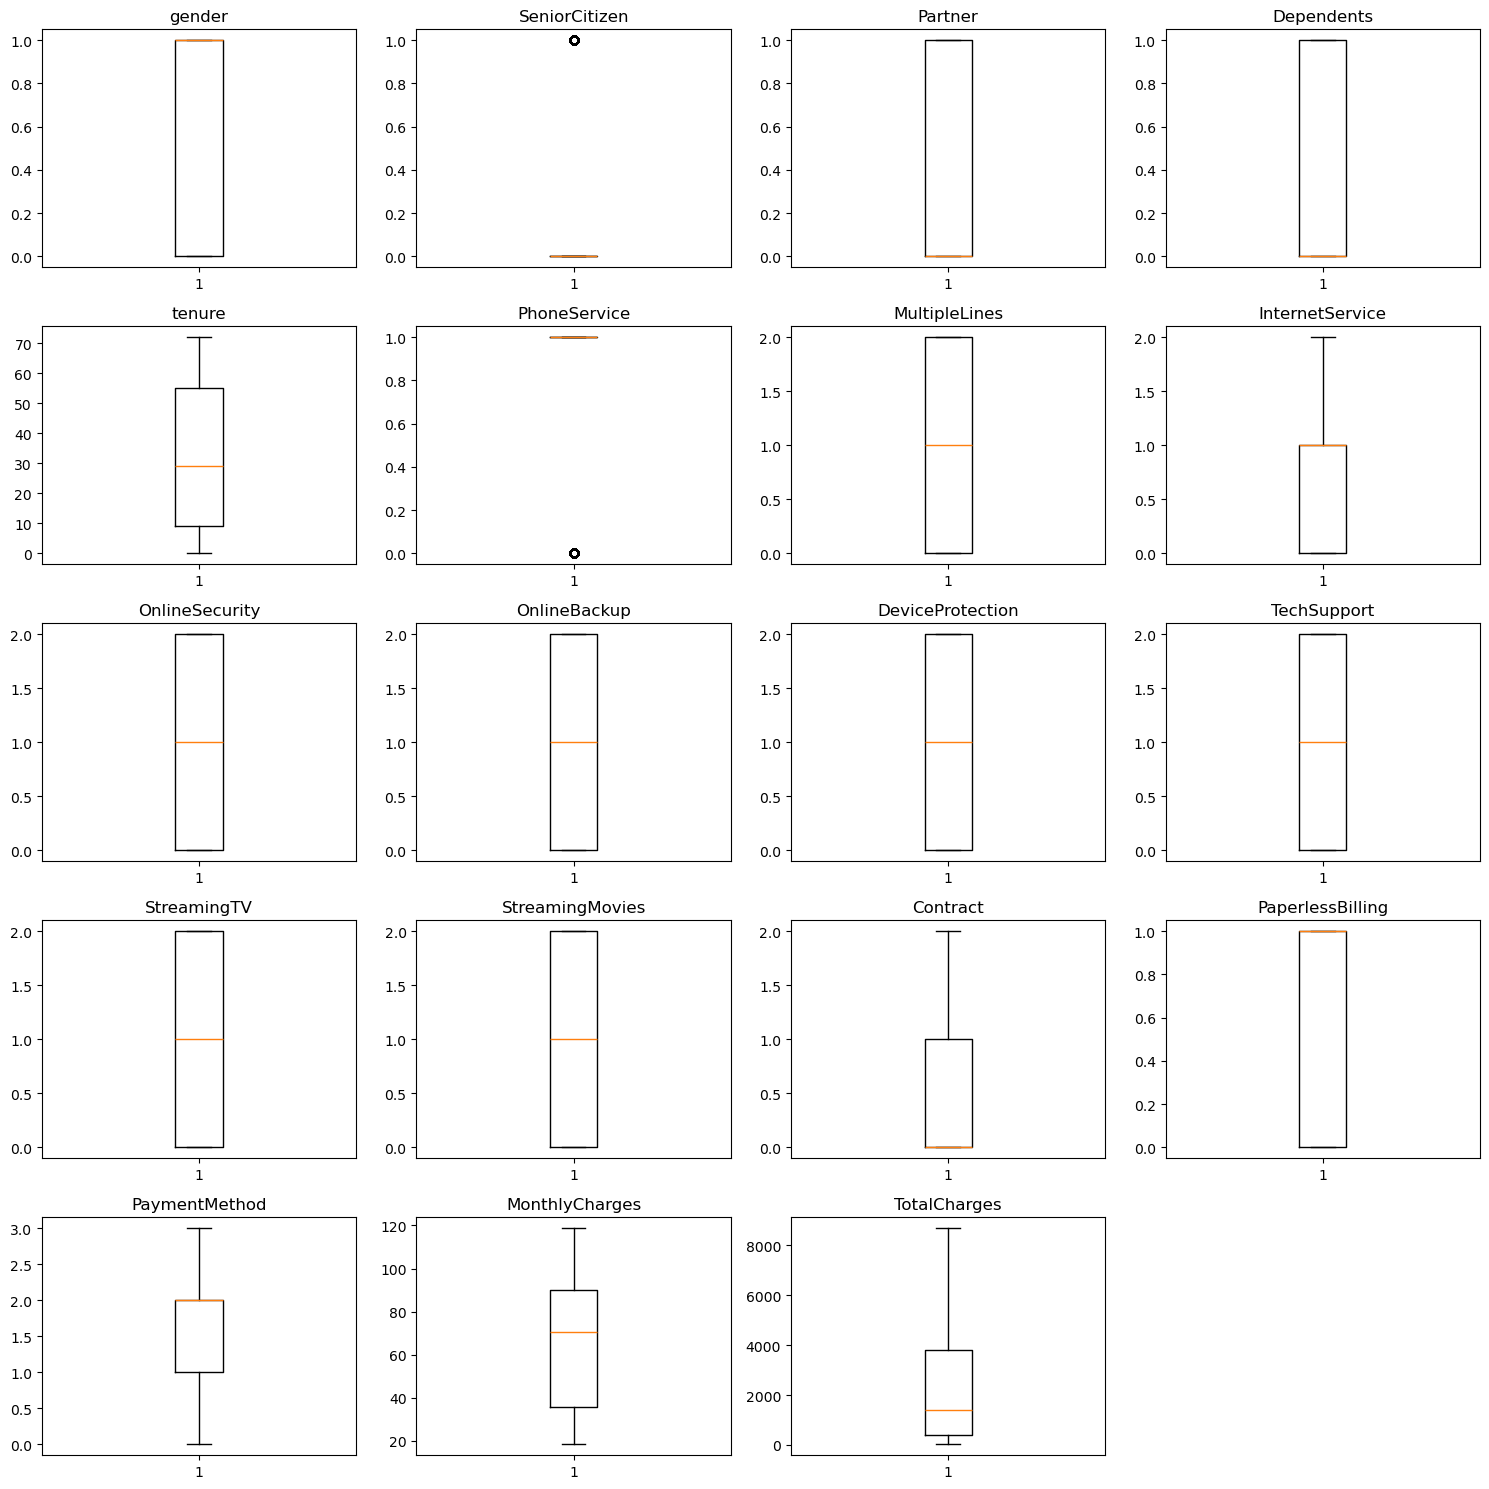

In [21]:
# Assuming x is your DataFrame and has enough columns
fig, ax = plt.subplots(nrows=5, ncols=4, figsize=(15, 15))

# Flatten the axes array for easy indexing
ax = ax.flatten()

# Loop through each column and plot
for idx, column in enumerate(x.columns):
    ax[idx].boxplot(x[column])
    ax[idx].set_title(column)
# Hide any unused subplots
for j in range(len(x.columns), len(ax)):
    ax[j].axis('off')

plt.tight_layout()
plt.show()

In [22]:
from sklearn.preprocessing import StandardScaler

In [23]:
x.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

In [24]:
feature_x=StandardScaler().fit_transform(x)

In [25]:
feature_x

array([[-1.00955867, -0.43991649,  1.03453023, ...,  0.39855772,
        -1.16032292, -0.99497138],
       [ 0.99053183, -0.43991649, -0.96662231, ...,  1.33486261,
        -0.25962894, -0.17387565],
       [ 0.99053183, -0.43991649, -0.96662231, ...,  1.33486261,
        -0.36266036, -0.96039939],
       ...,
       [-1.00955867, -0.43991649,  1.03453023, ...,  0.39855772,
        -1.1686319 , -0.85518222],
       [ 0.99053183,  2.27315869,  1.03453023, ...,  1.33486261,
         0.32033821, -0.87277729],
       [ 0.99053183, -0.43991649, -0.96662231, ..., -1.47405205,
         1.35896134,  2.01391739]])

In [26]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(feature_x,y,test_size=.25,random_state=42)

In [27]:
np.isnan(X_test).sum()

0

In [28]:
from sklearn.linear_model import LogisticRegression

In [29]:
model = LogisticRegression()

In [30]:
model.fit(X_train,y_train)

LogisticRegression()

In [90]:
y_pred=model.predict(X_test)

In [72]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [88]:
model.score(X_test,y_test)

0.8109028960817717

In [100]:
from sklearn.metrics import accuracy_score,confusion_matrix,ConfusionMatrixDisplay

In [94]:
score=accuracy_score(y_test,y_pred)
score

0.8109028960817717

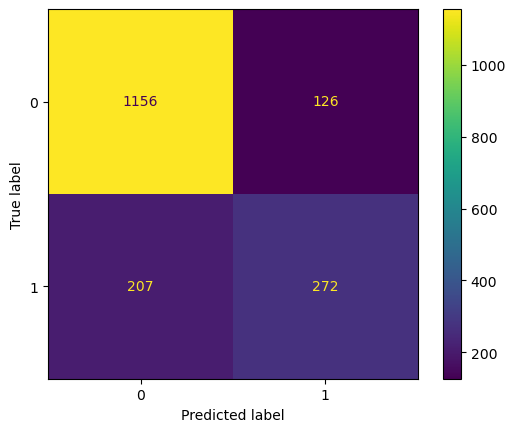

In [102]:
cm = confusion_matrix(y_test,y_pred)

cm_display = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = [0, 1])

cm_display.plot()
plt.show()